# WasteWise — EfficientNet-B0 with class-weighted loss

This experiment tested class-weighted cross-entropy as a single change to the
EfficientNet-B0 baseline. TrashNet's class imbalance and the baseline's lower
trash F1 motivated giving underrepresented training categories more weight.
All other experimental settings were retained.

## 1. Environment and run controls

Both experiments used the scientific Python environment and Apple MPS. The
package versions and project paths are shown below; the completed results were
loaded from their saved records.

In [1]:
from pathlib import Path
import os
import sys

# Set this only if the repository has moved and automatic discovery cannot find it.
ROOT_OVERRIDE = None
explicit_root = ROOT_OVERRIDE or os.environ.get("WASTEWISE_ROOT")
start = Path.cwd().resolve()
candidates = ([Path(explicit_root).expanduser()] if explicit_root else
              [start, *start.parents, Path.home() / "Projects" / "WasteWise"])
for candidate in candidates:
    candidate = candidate.resolve()
    if ((candidate / "src/experiment_data.py").is_file()
            and (candidate / "manifests/split_manifest.csv").is_file()):
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Set ROOT_OVERRIDE to the WasteWise project root and rerun this cell.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import experiment_data as datasets
from src import experiment_results as results

if Path(datasets.__file__).resolve().parent.parent != PROJECT_ROOT:
    raise RuntimeError("A different WasteWise checkout is cached. Restart this kernel.")
print("Project root: .")
print("Python interpreter:", Path(sys.executable).name)
display(results.package_table())
from src import weighted_experiment as weighted


Project root: .
Python interpreter: python


,Version
Package,
torch,2.14.1
torchvision,0.29.1
numpy,2.5.3
pandas,3.0.6
Pillow,12.3.0
matplotlib,3.11.2
ipykernel,7.4.0


In [2]:
MODE = "reload"  # "review", "train", or "reload"
MODEL_NAME = "efficientnet_b0"
BASELINE_RUN = "baseline_seed42_5epochs"
RUN_NAME = "weighted_ce_seed42_5epochs"
NOTEBOOK_NAME = "05_efficientnetb0_weighted_loss.ipynb"
RESTORE_CHECKPOINT = False  # Optional in reload mode; does not run inference.
DEVICE_PREFERENCE = "auto"
if MODE not in {"review", "train", "reload"}:
    raise ValueError("Choose review, train, or reload.")
if RUN_NAME != weighted.WEIGHTED_RUN:
    raise ValueError("Keep the approved run name for this single controlled experiment.")
run = None
model = None
run_config = None
print("Mode:", MODE)
print("Saved result directory:", results.run_path(PROJECT_ROOT, MODEL_NAME, RUN_NAME).relative_to(PROJECT_ROOT))

Mode: reload
Saved result directory: results/experiments/efficientnet_b0/weighted_ce_seed42_5epochs


## 2. Data, baseline reference and class weights

Both configurations used the same 1,765 training and 378 validation images.
Class weights were calculated from **training labels only** using
`weight_c = N_train / (N_classes * count_c)`. The table shows how smaller
categories received larger weights. Validation loss remained unweighted so
it could be compared with the baseline.

In [3]:
data = datasets.load_experiment_data(PROJECT_ROOT)
baseline_run = results.load_run(PROJECT_ROOT, MODEL_NAME, BASELINE_RUN, data,
                                require_checkpoint=MODE != "reload")
display(datasets.dataset_table(data))
display(weighted.weight_table(data).round(6))
print("Approved split SHA-256:", data["manifest_sha256"])
print("Validation rows SHA-256:", data["validation_rows_sha256"])
print("Class order:", data["classes"])
print(f"Reference validation macro-F1: {baseline_run['metrics']['macro_f1']:.4f}")

,Training,Validation
Category,,
cardboard,282,61
glass,348,75
metal,287,61
paper,416,89
plastic,336,72
trash,96,20


,Training images,Loss weight
Category,,
cardboard,282,1.043144
glass,348,0.845307
metal,287,1.024971
paper,416,0.707131
plastic,336,0.875496
trash,96,3.064236


Approved split SHA-256: b1e09badb3d1347f7b2d934c5824b10daa7b57f5a4e9c06be89d05b56659546f
Validation rows SHA-256: dd93ad52a04778024a57c864e86b944fb208b0ca70ebb498b580ecaa0b3e1484
Class order: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Reference validation macro-F1: 0.8722


## 3. Model initialization and experimental controls

Both runs started from the same ImageNet weights with a seed-42, six-output
linear classifier. Only its 7,686 parameters were trained; the feature extractor
remained frozen. Preprocessing used bicubic resizing to a 256-pixel shorter
edge, a 224 × 224 center crop, and ImageNet normalization, without augmentation.

Recorded checks matched the revised initialization to a reconstruction of the
baseline procedure; the original initial classifier had not been saved. The
optimizer, batch order, learning rate, and training budget were held fixed, as
summarized below.

In [4]:
def build_model(pretrained=True):
    """This notebook's architecture; no model is built until the function is called."""
    from torch import nn
    from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

    weights = EfficientNet_B0_Weights.IMAGENET1K_V1
    model = efficientnet_b0(weights=weights if pretrained else None)
    model.requires_grad_(False)
    feature_count = model.classifier[-1].in_features
    model.classifier = nn.Linear(feature_count, len(data["classes"]))
    return model, model.classifier, weights.transforms(), weights

In [5]:
if MODE in {"review", "train"}:
    if MODE == "train":
        results.require_new_run(PROJECT_ROOT, MODEL_NAME, RUN_NAME)
    from src import experiment_training as training
    device = training.select_device(DEVICE_PREFERENCE)
    model, head, transform, run_config = weighted.prepare_experiment(
        data, baseline_run, build_model, device, NOTEBOOK_NAME)
    weighted.validate_training_start(data, model, head, transform, run_config, device)
    checks = run_config["initialization_verification"]
    display(pd.Series({
        "Architecture definition matches baseline": checks["builder_matches_baseline"],
        "All reconstructed initial tensors match": checks["all_initial_tensors_equal"],
        "Frozen features match baseline checkpoint": checks["frozen_features_match_baseline_checkpoint"],
        "Seeded training batch indices match": checks["shuffle_indices_equal"],
        "All other recorded settings match": weighted.validate_controlled_config(data, baseline_run, run_config),
    }, name="Passed").to_frame())
    print("Reconstructed baseline initial SHA-256:", checks["reconstructed_baseline_state_sha256"])
    print("Revised model initial SHA-256:         ", checks["revised_initial_state_sha256"])
    print(checks["limitation"])
elif MODE == "reload":
    run = weighted.load_weighted_run(data, baseline_run, require_checkpoint=RESTORE_CHECKPOINT)
    run_config = run["config"]
    if RESTORE_CHECKPOINT:
        from src import experiment_training as training
        device = training.select_device(DEVICE_PREFERENCE)
        model, head, transform, weights = build_model(pretrained=False)
        model = training.restore_checkpoint(model, run, data, device)
        print("Saved checkpoint restored without training or new inference.")

keys = ["loss", "weights", "seed", "feature_mode", "head", "trainable_parameters",
        "optimizer", "learning_rate", "optimizer_kwargs", "weight_decay", "batch_size",
        "epochs", "checkpoint_selection", "augmentation", "preprocessing", "precision",
        "num_workers", "device", "n_train", "n_validation", "package_versions"]
configuration_table = pd.DataFrame({
    "Unweighted baseline": {key: str(baseline_run["config"][key]) for key in keys},
    "Weighted experiment": {key: str(run_config[key]) for key in keys},
})
display(configuration_table)
classifier_summary = run_config["architecture"].split("(classifier): ", 1)[1].splitlines()[0]
print("Replacement classifier:", classifier_summary)

,Unweighted baseline,Weighted experiment
loss,CrossEntropyLoss,ClassWeightedCrossEntropyLoss
weights,EfficientNet_B0_Weights.IMAGENET1K_V1,EfficientNet_B0_Weights.IMAGENET1K_V1
seed,42,42
feature_mode,frozen_eval,frozen_eval
head,single_linear_layer,single_linear_layer
trainable_parameters,7686,7686
optimizer,Adam,Adam
learning_rate,0.001,0.001
optimizer_kwargs,"{'betas': [0.9, 0.999], 'eps': 1e-08, 'amsgrad...","{'betas': [0.9, 0.999], 'eps': 1e-08, 'amsgrad..."
weight_decay,0.0,0.0


Replacement classifier: Linear(in_features=1280, out_features=6, bias=True)


## 4. Saved training history

Both runs completed five epochs. Checkpoints were selected by the highest
validation macro-F1, retaining the earliest epoch on a tie. The table preserves
the weighted run's losses, metrics, and epoch timings.

In [6]:
if MODE == "train":
    run = training.train_weighted(data, model, head, transform, run_config, device)
    run = weighted.load_weighted_run(data, baseline_run, require_checkpoint=True)
elif MODE == "reload":
    print("Loaded the saved weighted experiment; no training or new timing measurements.")
else:
    print("Review complete. No training was run and no experiment results were created.")
if run is not None:
    display(run["history"])
    print("Saved experiment:", run["directory"].relative_to(PROJECT_ROOT))

Loaded the saved weighted experiment; no training or new timing measurements.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,epoch_seconds,train_unweighted_loss
0,1,1.025410,0.682720,0.629424,0.817460,0.787390,13.679522,1.007059
1,2,0.535774,0.856091,0.507046,0.835979,0.809460,10.263478,0.507506
2,3,0.408268,0.886686,0.425604,0.873016,0.848518,10.342147,0.405101
3,4,0.337134,0.907082,0.433437,0.841270,0.813273,10.099393,0.330715
4,5,0.287029,0.926912,0.400989,0.867725,0.842954,10.242036,0.289895


Saved experiment: results/experiments/efficientnet_b0/weighted_ce_seed42_5epochs


## 5. Learning curves

Unweighted losses allow comparison between runs; the weighted training objective
is shown separately. Training loss declined throughout the revised run, but
validation macro-F1 peaked at epoch 3, fell at epoch 4, and recovered only
partially at epoch 5. The selected checkpoints are marked on the F1 curves.

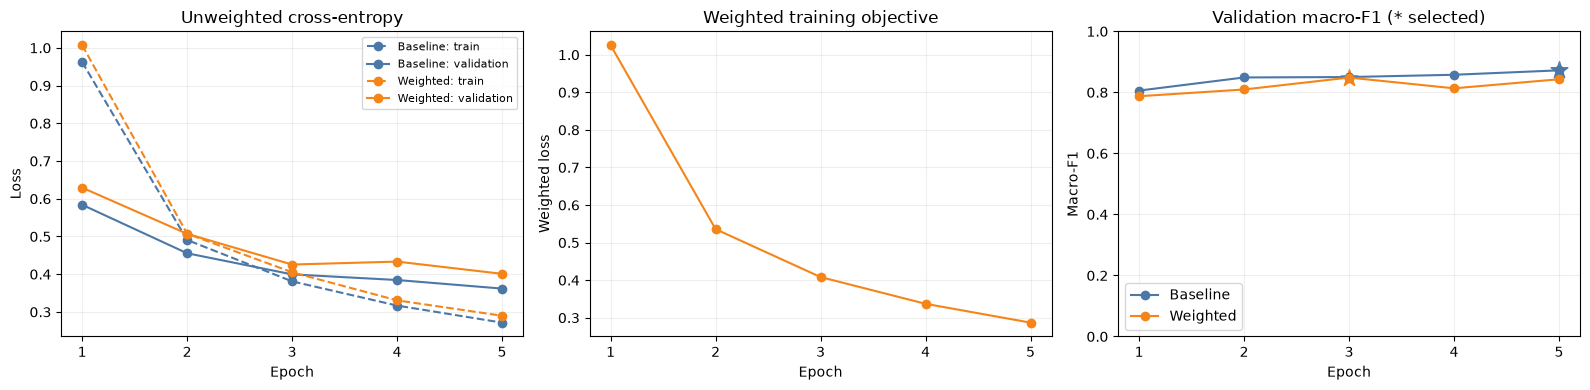

In [7]:
if run is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for label, item, color in [("Baseline", baseline_run, "#4c78a8"),
                               ("Weighted", run, "#f58518")]:
        history = item["history"]
        train_column = "train_unweighted_loss" if item is run else "train_loss"
        axes[0].plot(history["epoch"], history[train_column], "--o", color=color, label=f"{label}: train")
        axes[0].plot(history["epoch"], history["validation_loss"], "-o", color=color, label=f"{label}: validation")
        axes[2].plot(history["epoch"], history["validation_macro_f1"], "-o", color=color, label=label)
        best_epoch = item["metrics"]["best_epoch"]
        axes[2].scatter([best_epoch], [item["metrics"]["macro_f1"]], marker="*", s=160, color=color)
    axes[0].set(title="Unweighted cross-entropy", xlabel="Epoch", ylabel="Loss")
    axes[1].plot(run["history"]["epoch"], run["history"]["train_loss"], "-o", color="#f58518")
    axes[1].set(title="Weighted training objective", xlabel="Epoch", ylabel="Weighted loss")
    axes[2].set(title="Validation macro-F1 (* selected)", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))
    axes[0].legend(fontsize=8)
    axes[2].legend()
    for ax in axes:
        ax.set_xticks(run["history"]["epoch"])
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
else:
    print("Revised learning curves are pending a real training run.")

## 6. Validation performance and practical cost

The selected checkpoints were compared on the same validation images. F1 fell
for five categories, including plastic, metal, and cardboard; paper was the
only category to improve.

Training time and local latency were similar. Both runs used batch-one timing
on MPS, with 10 warm-up passes and 50 timed repetitions over 20 seeded validation
images. End-to-end timing included decoding, preprocessing, transfer, and
prediction, but excluded model startup and application overhead.

Configuration,Unweighted baseline,Weighted cross-entropy,Change (weighted − baseline)
Macro-F1,0.8722,0.8485,-0.0237
Accuracy,0.8915,0.8730,-0.0185
Weighted F1,0.8917,0.8755,-0.0162
Trash precision,0.7143,0.5714,-0.1429
Trash recall,0.7500,0.8000,0.0500
Trash F1,0.7317,0.6667,-0.0650
Validation loss (unweighted),0.3619,0.4256,0.0637
Validation images,378.0000,378.0000,0.0000
Best epoch,5.0000,3.0000,-2.0000
Training seconds,53.7225,54.6284,0.9059


Verified: both prediction files contain the exact same approved validation paths and labels.


precision  recall      f1  support  \
Configuration          Category                                        
Unweighted baseline    cardboard     0.8852  0.8852  0.8852       61   
                       glass         0.8933  0.8933  0.8933       75   
                       metal         0.8923  0.9508  0.9206       61   
                       paper         0.9405  0.8876  0.9133       89   
                       plastic       0.8889  0.8889  0.8889       72   
                       trash         0.7143  0.7500  0.7317       20   
Weighted cross-entropy cardboard     0.8833  0.8689  0.8760       61   
                       glass         0.8608  0.9067  0.8831       75   
                       metal         0.8594  0.9016  0.8800       61   
                       paper         0.9634  0.8876  0.9240       89   
                       plastic       0.9077  0.8194  0.8613       72   
                       trash         0.5714  0.8000  0.6667       20   

                                  one_vs_rest_accuracy  
Configuration          Category                         
Unweighted baseline    cardboard                0.9630  
                       glass                    0.9577  
                       metal                    0.9735  
                       paper                    0.9603  
                       plastic                  0.9577  
                       trash                    0.9709  
Weighted cross-entropy cardboard                0.9603  
                       glass                    0.9524  
                       metal                    0.9603  
                       paper                    0.9656  
                       plastic                  0.9497  
                       trash                    0.9577

,Baseline,Weighted,Change
Category,,,
cardboard,0.8852,0.8760,-0.0092
glass,0.8933,0.8831,-0.0102
metal,0.9206,0.8800,-0.0406
paper,0.9133,0.9240,0.0107
plastic,0.8889,0.8613,-0.0276
trash,0.7317,0.6667,-0.0650


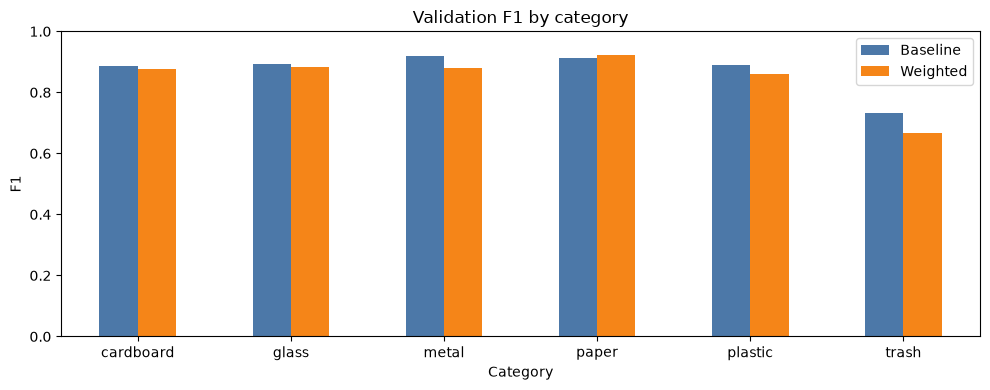

In [8]:
if run is not None:
    comparison = weighted.comparison_table(data, baseline_run, run)
    comparison_with_changes = comparison.T.copy()
    comparison_with_changes["Change (weighted − baseline)"] = (
        comparison_with_changes["Weighted cross-entropy"] - comparison_with_changes["Unweighted baseline"])
    display(comparison_with_changes.round(4))
    print("Verified: both prediction files contain the exact same approved validation paths and labels.")
    per_class = pd.concat({
        "Unweighted baseline": pd.DataFrame(baseline_run["metrics"]["per_class"]).set_index("class"),
        "Weighted cross-entropy": pd.DataFrame(run["metrics"]["per_class"]).set_index("class"),
    }, names=["Configuration", "Category"])
    display(per_class.round(4))
    f1 = pd.DataFrame({
        "Baseline": per_class.loc["Unweighted baseline", "f1"],
        "Weighted": per_class.loc["Weighted cross-entropy", "f1"],
    }).reindex(data["classes"])
    display(f1.assign(Change=f1["Weighted"] - f1["Baseline"]).round(4))
    ax = f1.plot.bar(figsize=(10, 4), rot=0, color=["#4c78a8", "#f58518"])
    ax.set(title="Validation F1 by category", ylabel="F1", xlabel="Category", ylim=(0, 1))
    plt.tight_layout()
    plt.show()
else:
    print("Revised metrics and latency are pending. Saved baseline results:")
    display(results.comparison_table([baseline_run]).set_index("Model").T.round(4))

## 7. Confusion matrices

Trash recall rose from 0.75 to 0.80, but false-positive trash predictions doubled
from 6 to 12. Precision therefore fell from 0.7143 to 0.5714, outweighing the
recall gain and reducing trash F1 from 0.7317 to 0.6667. Both matrices use the
same count scale.

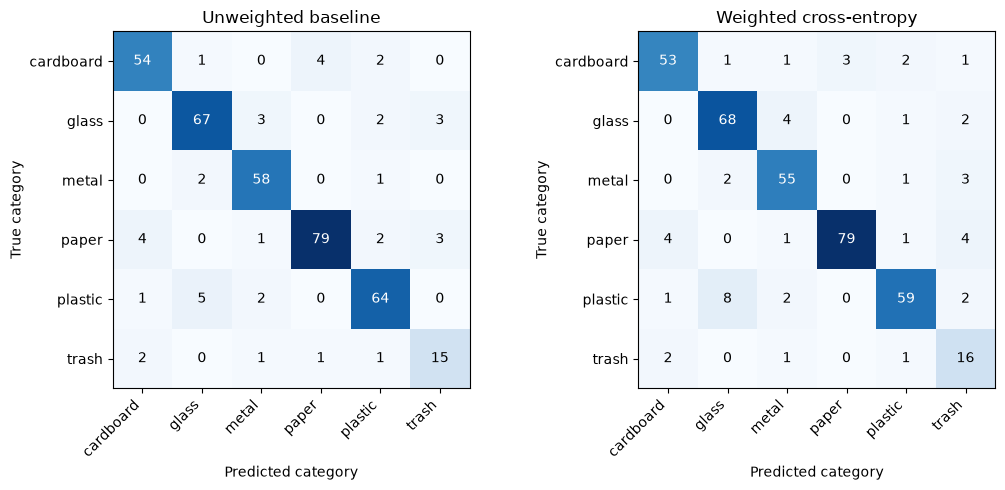

In [9]:
if run is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    maximum = max(max(map(max, item["metrics"]["confusion_matrix"])) for item in [baseline_run, run])
    for ax, title, item in zip(axes, ["Unweighted baseline", "Weighted cross-entropy"], [baseline_run, run]):
        results.plot_confusion(item, ax=ax)
        ax.set_title(title)
        ax.images[0].set_clim(0, maximum)
    fig.tight_layout()
    plt.show()
else:
    print("The paired confusion matrices will appear after training or reload.")

## 8. Real validation predictions and error analysis

The grids show six low-confidence correct predictions and the eight most
confident errors. All six errors with confidence above 80% were also incorrect
in the baseline, including four plastic bottles predicted as glass. High
confidence did not ensure correct material recognition.

Across the validation set, weighting corrected three baseline mistakes and
introduced ten new errors, as summarized below.

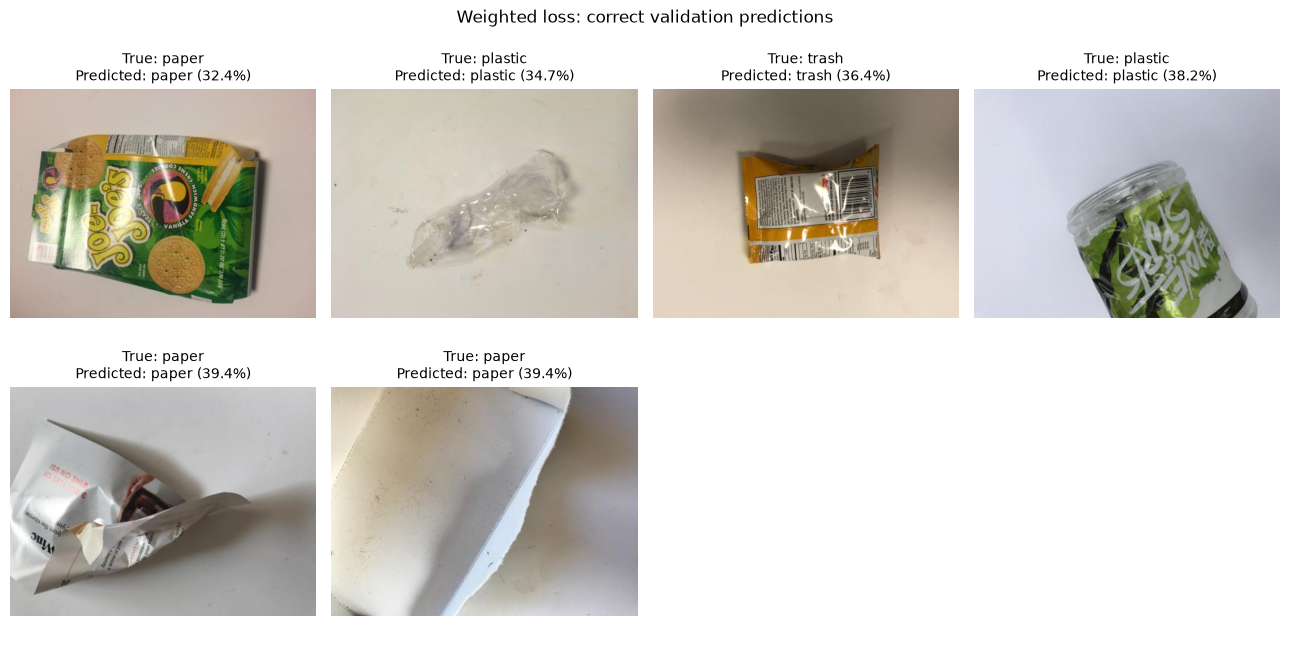

,path,true_label,predicted_label,confidence,correct
357,plastic/plastic95.jpg,plastic,glass,0.959479,False
356,plastic/plastic94.jpg,plastic,glass,0.918639,False
335,plastic/plastic370.jpg,plastic,glass,0.852088,False
353,plastic/plastic69.jpg,plastic,glass,0.847295,False
278,paper/paper590.jpg,paper,trash,0.825704,False
48,cardboard/cardboard392.jpg,cardboard,paper,0.807284,False
264,paper/paper533.jpg,paper,cardboard,0.775469,False
125,glass/glass443.jpg,glass,metal,0.761856,False


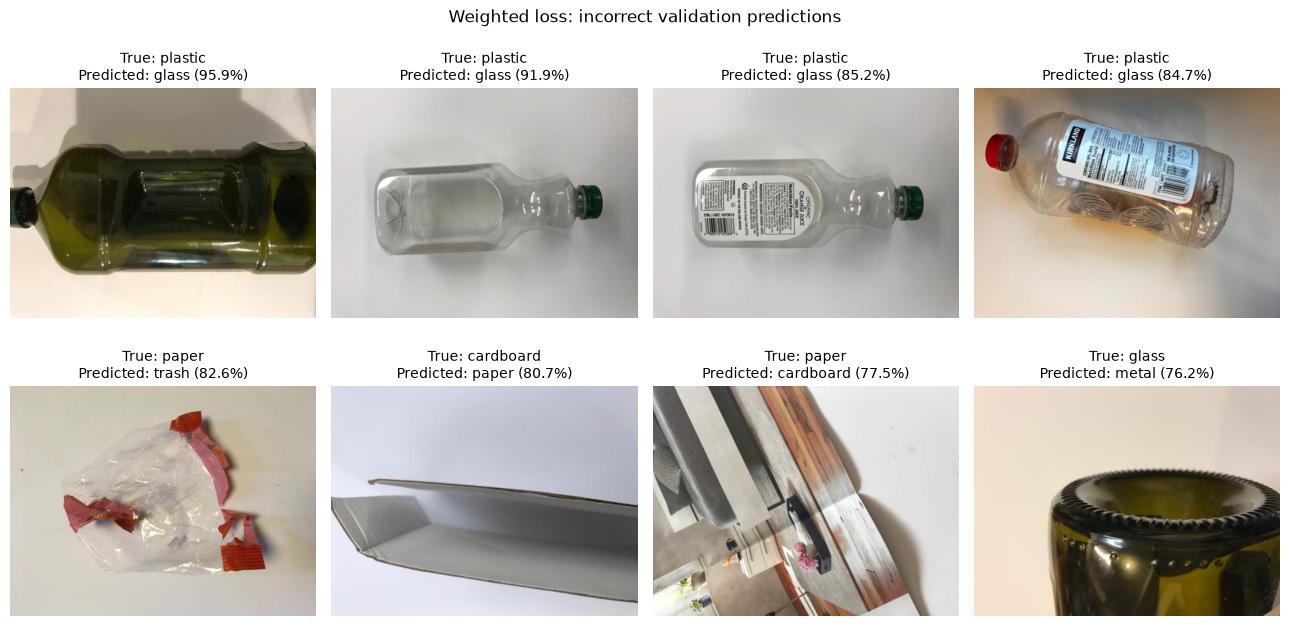

,true_label,predicted_label,Images
0,plastic,glass,8
1,paper,cardboard,4
2,paper,trash,4
3,glass,metal,4
4,cardboard,paper,3


,Images
Change,
New error,10
Corrected,3


,path,true_label,predicted_label_baseline,correct_baseline,predicted_label_weighted,correct_weighted,Change
9,cardboard/cardboard150.jpg,cardboard,cardboard,True,trash,False,New error
129,glass/glass497.jpg,glass,plastic,False,glass,True,Corrected
145,metal/metal15.jpg,metal,metal,True,trash,False,New error
168,metal/metal298.jpg,metal,metal,True,trash,False,New error
181,metal/metal363.jpg,metal,metal,True,trash,False,New error
258,paper/paper477.jpg,paper,paper,True,cardboard,False,New error
280,paper/paper592.jpg,paper,cardboard,False,paper,True,Corrected
364,trash/trash19.jpg,trash,paper,False,trash,True,Corrected


In [10]:
if run is not None:
    correct_examples = results.prediction_examples(run, correct=True, limit=6)
    results.plot_predictions(data, correct_examples, "Weighted loss: correct validation predictions")
    plt.show()
    errors = results.prediction_examples(run, correct=False, limit=8)
    display(errors[["path", "true_label", "predicted_label", "confidence", "correct"]])
    title = "Weighted loss: incorrect validation predictions" if (~run["predictions"]["correct"]).any() else "No errors: weak correct predictions"
    results.plot_predictions(data, errors, title)
    plt.show()
    display(results.confusion_pairs(run))
    paired = baseline_run["predictions"][["path", "true_label", "predicted_label", "correct"]].merge(
        run["predictions"][["path", "predicted_label", "correct"]],
        on="path", suffixes=("_baseline", "_weighted"), validate="one_to_one")
    changed = paired.loc[paired["correct_baseline"] != paired["correct_weighted"]].copy()
    changed["Change"] = changed["correct_weighted"].map({True: "Corrected", False: "New error"})
    display(changed["Change"].value_counts().rename("Images").to_frame())
    display(changed.groupby("Change", group_keys=False).head(5))
else:
    print("Revised prediction examples are pending a real training run.")

## 9. Measured outcome and interpretation

In [11]:
if run is not None:
    display(Markdown(
        f"Validation macro-F1 decreased from **{baseline_run['metrics']['macro_f1']:.4f}** "
        f"to **{run['metrics']['macro_f1']:.4f}**, and accuracy from "
        f"**{baseline_run['metrics']['accuracy']:.2%}** to **{run['metrics']['accuracy']:.2%}**."
    ))
else:
    print("Saved weighted results are not loaded.")

Validation macro-F1 decreased from **0.8722** to **0.8485**, and accuracy from **89.15%** to **87.30%**.

### Conclusion

The original unweighted EfficientNet-B0 remained the selected model. Class
weighting did not improve overall validation performance in this five-epoch
experiment; the result does not rule out benefits under other settings.

The comparison used one seed and one split, with only 20 trash validation images.
Unresolved related-image identities remained a limitation. The held-out test
set was not evaluated.